# Retail Sales Data Analysis Using Python

## Project Overview

This project explores a retail sales dataset using Python to identify sales patterns, compare product categories, and understand customer transaction values.

## Objectives

- Identify the product category generating the highest total revenue.
- Compare average transaction values across categories.
- Analyse monthly revenue trends.
- Inspect the dataset for missing values, duplicate records, and data type issues.

## Tools and Libraries

- Python
- Pandas — data manipulation and analysis
- Matplotlib — data visualisation
- Google Colab — development environment

## Key Skills Demonstrated

Data inspection, exploratory data analysis (EDA), grouping and aggregation, date-based analysis, data visualisation, and interpretation of business findings.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving retail_sales_dataset.csv to retail_sales_dataset (1).csv


In [2]:
import pandas as pd
df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check column names and data types
df.info()

# 3. Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


In [4]:
# See the available product categories
print("\nProduct categories:")
print(df["Product Category"].value_counts())

# Understand the distribution of transaction amounts
print("\nTransaction amount summary:")
print(df["Total Amount"].describe())



Product categories:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

Transaction amount summary:
count    1000.000000
mean      456.000000
std       559.997632
min        25.000000
25%        60.000000
50%       135.000000
75%       900.000000
max      2000.000000
Name: Total Amount, dtype: float64


## Which category generates the most revenue?

In [5]:
# Calculate total revenue for each product category
category_revenue = df.groupby("Product Category")["Total Amount"].sum()

# Display categories from highest to lowest revenue
category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


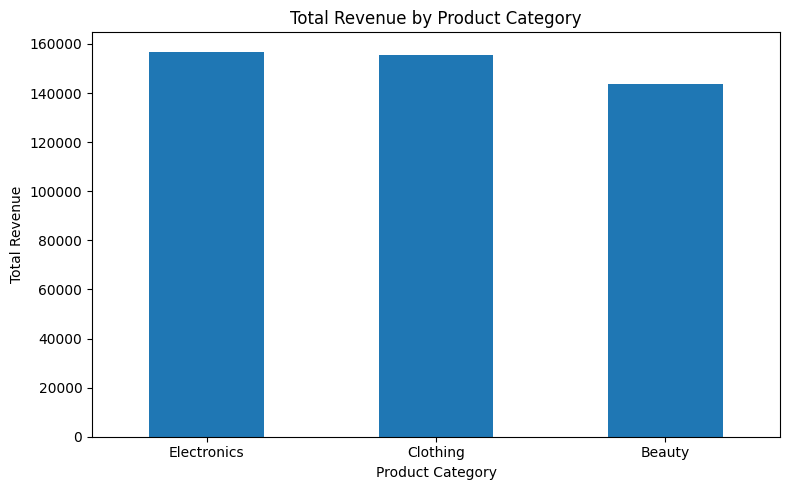

In [6]:
import matplotlib.pyplot as plt

category_revenue.plot(kind="bar", figsize=(8, 5))

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


CONCLUSION:
1. Electronics generates the most revenue: 156,905.
2. Clothing is a very close second, with only a 1,325 difference.
3. Beauty generates the lowest revenue among the three categories.

## Which product category has the highest average transaction value?

In [7]:
# Calculate average transaction amount for each category
category_average = (
    df.groupby("Product Category")["Total Amount"]
    .mean()
    .sort_values(ascending=False)
)

print(category_average)


Product Category
Beauty         467.475570
Electronics    458.786550
Clothing       443.247863
Name: Total Amount, dtype: float64


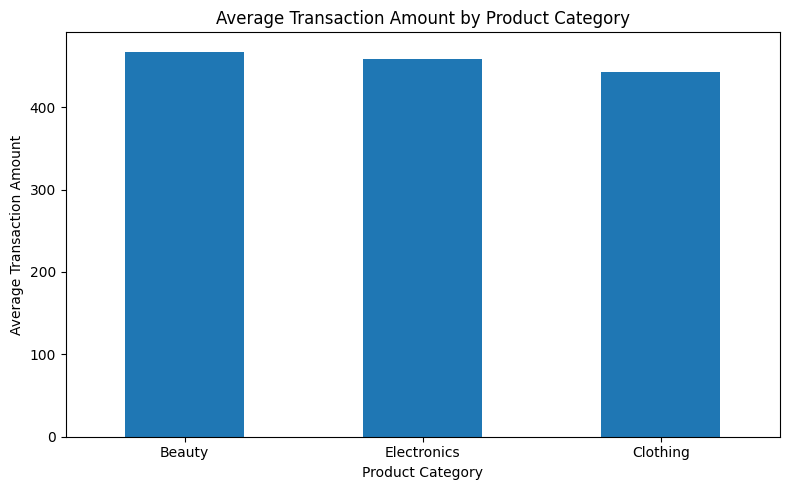

In [8]:
category_average.plot(kind="bar", figsize=(8, 5))

plt.title("Average Transaction Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Transaction Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


CONCLUSION: Beauty has the highest average transaction value (467.48), followed by Electronics (458.79) and Clothing (443.25).

## How do sales change over time?

In [9]:
# Convert dates into proper datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Extract the month and calculate monthly revenue
df["Month"] = df["Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Total Amount"].sum()

print(monthly_revenue)


Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


In [10]:
print("First transaction:", df["Date"].min())
print("Last transaction:", df["Date"].max())

print("\nTransactions by month:")
print(df["Month"].value_counts().sort_index())


First transaction: 2023-01-01 00:00:00
Last transaction: 2024-01-01 00:00:00

Transactions by month:
Month
2023-01     76
2023-02     85
2023-03     73
2023-04     86
2023-05    105
2023-06     77
2023-07     72
2023-08     94
2023-09     65
2023-10     96
2023-11     78
2023-12     91
2024-01      2
Freq: M, Name: count, dtype: int64


Note: Since, January 2024 has only two transactions, so its monthly figures aren't directly comparable with complete months.

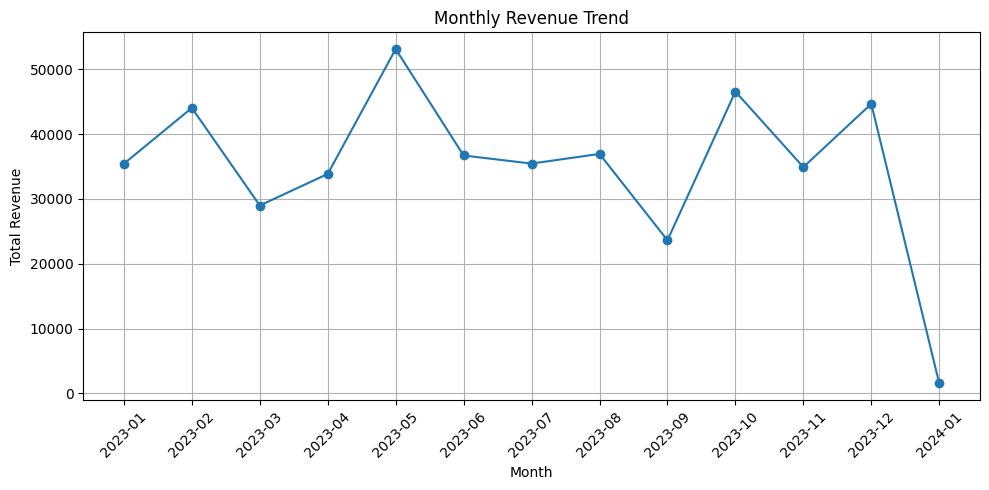

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


CONCLUSION: May 2023 has the highest monthly revenue (53,150), while September has the lowest among the complete months (23,620).

## Average revenue per transaction for each month

In [12]:
monthly_average = (
    df.groupby("Month")["Total Amount"]
    .mean()
)

print(monthly_average.round(2))


Month
2023-01    466.45
2023-02    518.35
2023-03    397.12
2023-04    393.84
2023-05    506.19
2023-06    476.82
2023-07    492.57
2023-08    393.19
2023-09    363.38
2023-10    485.21
2023-11    447.69
2023-12    491.10
2024-01    765.00
Freq: M, Name: Total Amount, dtype: float64


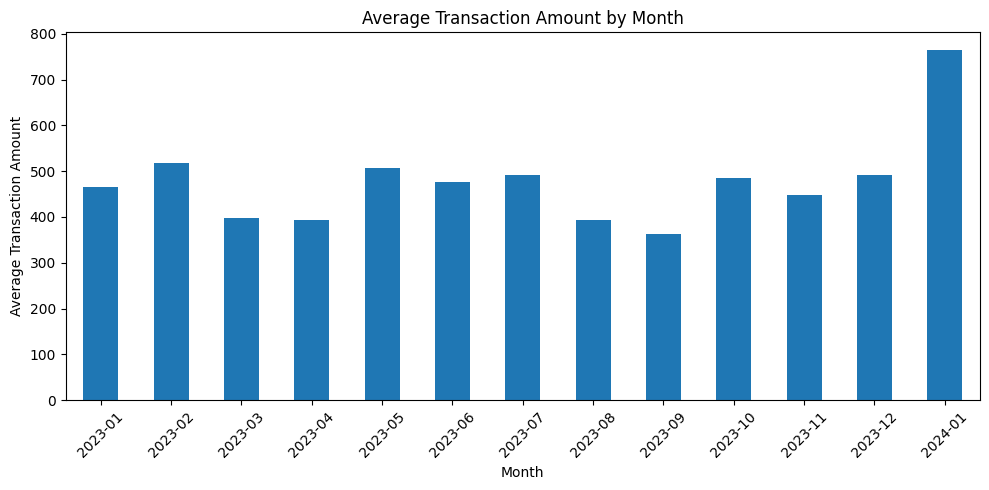

In [13]:
monthly_average.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Transaction Amount by Month")
plt.xlabel("Month")
plt.ylabel("Average Transaction Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Key Findings — Retail Sales Analysis

1. **Top revenue category:** Electronics generated the highest total revenue at 156,905, closely followed by Clothing at 155,580.

2. **Highest average transaction value:** Beauty recorded the highest average transaction amount at approximately 467.48, while Clothing recorded the lowest at approximately 443.25.

3. **Monthly sales trend:** May 2023 had the highest monthly revenue at 53,150, while September 2023 had the lowest among the full months at 23,620.

4. **Incomplete final month:** January 2024 contained only two transactions. Its revenue and average transaction value should not be compared directly with complete months.

5. **Data quality:** The dataset contained 1,000 records, no missing values, and no completely duplicated rows.
